# Breast cancer on ultrasound: classification and segmentation

Two models trained on breast ultrasound images, both using a ResNet-34 pretrained on ImageNet:
- a classifier: normal, benign or malignant
- a U-Net that segments the lesion

I train on BUSI ([Al-Dhabyani et al., 2020](https://doi.org/10.1016/j.dib.2019.104863)), 780 images from 600 women scanned in 2018 at Baheya Hospital in Cairo, with a mask for each lesion. Careful with this dataset: 155 of the images are duplicates ([Pawłowska et al., 2023](https://doi.org/10.1016/j.dib.2023.109247)). With a plain random split, copies of training images end up in the test set and the scores look better than they really are, so I remove the ones I can find first (section 3).

To see how the models behave on data from somewhere else, I also test them on BUS-BRA ([Gómez-Flores et al., 2024](https://doi.org/10.1002/mp.16812)), 1875 images from 1064 patients in Brazil, all biopsy-proven. It's never used for training.

Made for Colab with a T4 GPU. It also runs on CPU, just slowly.

Research / learning project, not for medical use.

## 1. Setup

In [2]:
%pip install -q kagglehub

In [3]:
import hashlib
import random
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy import ndimage
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import tv_tensors
from torchvision.models import ResNet34_Weights, resnet34
from torchvision.transforms import v2 as T

In [4]:
SEED = 42
IMG_SIZE = 256   # has to be a multiple of 32 for the unet
BATCH_SIZE = 16
EPOCHS_CLS = 30
EPOCHS_SEG = 40
PATIENCE = 8     # early stopping
LR = 3e-4
PRETRAINED = True

DUP_THRESHOLD = 0.9   # see section 3
MIN_LESION_PX = 50    # predicted blobs smaller than this are removed

RUN_EXTERNAL_TEST = True
# set these if you already have the datasets somewhere
BUSI_DIR = None
BUSBRA_DIR = None

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

CLASSES = ["normal", "benign", "malignant"]

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
USE_AMP = DEVICE.type == "cuda"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
print("torch", torch.__version__, "on", DEVICE)

torch 2.11.0+cu130 on cuda


## 2. Loading BUSI

`kagglehub` downloads it from Kaggle (no account needed). There's one folder per class and each image has its mask next to it, e.g. `benign (12).png` and `benign (12)_mask.png`. When an image has two lesions there's also a `_mask_1`, so I merge all the masks of an image into one.

In [5]:
def find_busi_root(path):
    # the kaggle archive has the class folders one level down
    for folder in [Path(path), *sorted(Path(path).rglob("*"))]:
        if all((folder / c).is_dir() for c in CLASSES):
            return folder
    raise FileNotFoundError(f"no normal/benign/malignant folders in {path}")


if BUSI_DIR is None:
    import kagglehub
    BUSI_DIR = kagglehub.dataset_download("aryashah2k/breast-ultrasound-images-dataset")
busi_root = find_busi_root(BUSI_DIR)
print(busi_root)

100%|██████████| 195M/195M [00:07<00:00, 26.5MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/aryashah2k/breast-ultrasound-images-dataset/versions/1/Dataset_BUSI_with_GT


In [6]:
rows = []
for label in CLASSES:
    for f in sorted((busi_root / label).glob("*.png")):
        if "_mask" in f.stem:
            continue
        mask_files = sorted(f.parent.glob(f.stem + "_mask*.png"))
        rows.append({"name": f.name, "label": label, "image": f, "masks": mask_files})
df = pd.DataFrame(rows)
df["y"] = df["label"].map(CLASSES.index)

print(len(df), "images")
print(df["label"].value_counts()[CLASSES].to_string())
print("more than one mask:", (df["masks"].str.len() > 1).sum())
print("no mask:", (df["masks"].str.len() == 0).sum())

780 images
label
normal       133
benign       437
malignant    210
more than one mask: 17
no mask: 0


In [7]:
def load_gray(path):
    return np.array(Image.open(path).convert("L"))


def pad_resize(arr, size, nearest=False):
    # pad to a square first, otherwise the resize squashes the lesion
    h, w = arr.shape
    s = max(h, w)
    out = np.zeros((s, s), dtype=arr.dtype)
    top, left = (s - h) // 2, (s - w) // 2
    out[top:top + h, left:left + w] = arr
    resample = Image.Resampling.NEAREST if nearest else Image.Resampling.BILINEAR
    return np.array(Image.fromarray(out).resize((size, size), resample))


def load_case(image_path, mask_paths, size=IMG_SIZE):
    img = load_gray(image_path)
    mask = np.zeros(img.shape, dtype=np.uint8)
    for p in mask_paths:
        m = load_gray(p)
        if m.shape != img.shape:   # just in case a mask doesn't have the image size
            m = np.array(Image.fromarray(m).resize(img.shape[::-1], Image.Resampling.NEAREST))
        mask |= (m > 127).astype(np.uint8)
    return pad_resize(img, size), pad_resize(mask, size, nearest=True).astype(bool)


images, masks = [], []
for r in df.itertuples():
    img, mask = load_case(r.image, r.masks)
    images.append(img)
    masks.append(mask)
images, masks = np.stack(images), np.stack(masks)
print(images.shape, masks.shape)

(780, 256, 256) (780, 256, 256)


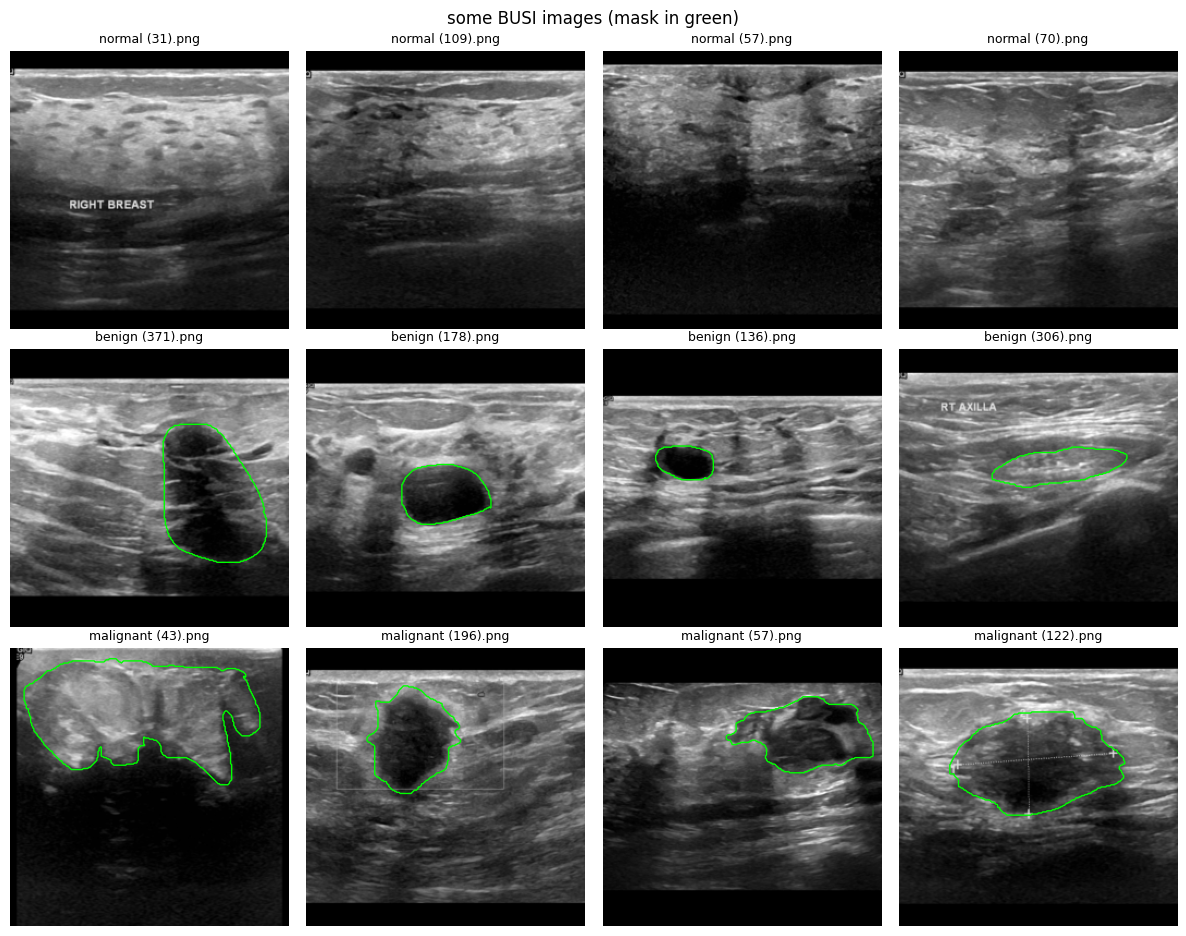

In [8]:
def show(ax, img, gt=None, pred=None, title=""):
    ax.imshow(img, cmap="gray")
    if gt is not None and gt.any():
        ax.contour(gt, levels=[0.5], colors="lime", linewidths=1)
    if pred is not None and pred.any():
        ax.contour(pred, levels=[0.5], colors="red", linewidths=1)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


fig, axes = plt.subplots(3, 4, figsize=(12, 9.5))
for row, label in zip(axes, CLASSES):
    idx = rng.choice(np.flatnonzero(df["label"] == label), 4, replace=False)
    for ax, i in zip(row, idx):
        show(ax, images[i], masks[i], title=df.at[i, "name"])
plt.suptitle("some BUSI images (mask in green)")
plt.tight_layout()
plt.show()

## 3. Removing duplicates

Correlating raw pixels isn't a good idea here because all ultrasound images share the same layout (black borders, darker with depth), so two different scans can still correlate a lot. Each image gets a "fingerprint" instead:
1. resize to 128x128
2. subtract a blurred copy of itself, which only keeps the fine texture (speckle, edges)
3. subtract the mean fingerprint of the dataset, to remove what all scans have in common

Two images whose fingerprints correlate above `DUP_THRESHOLD` are counted as the same image. Some copies come with another mask, a few even with another label. I group the pairs (if a = b and b = c, all three go together), keep one image per group and drop the groups where the labels don't agree. Cropped or zoomed copies won't be caught by this.

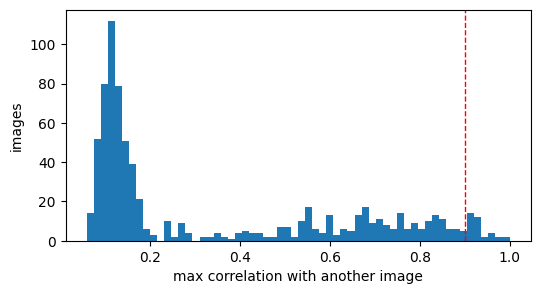

18 pairs above the threshold
36 images in 18 groups of duplicates
4 of them have a copy with a different label


In [9]:
def fingerprint(path, size=128):
    img = Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)
    x = torch.from_numpy(np.asarray(img, dtype=np.float32))[None, None]
    blurred = F.avg_pool2d(x, 9, stride=1, padding=4, count_include_pad=False)
    return (x - blurred).flatten()


fps = torch.stack([fingerprint(p) for p in df["image"]])
fps = fps - fps.mean(0)
fps = fps - fps.mean(1, keepdim=True)
fps = F.normalize(fps, dim=1)
corr = (fps @ fps.T).numpy()   # pearson correlation for every pair
np.fill_diagonal(corr, -1)

plt.figure(figsize=(6, 3))
plt.hist(corr.max(1), bins=60)
plt.axvline(DUP_THRESHOLD, color="red", ls="--", lw=1)
plt.xlabel("max correlation with another image")
plt.ylabel("images")
plt.show()

pairs = np.argwhere(np.triu(corr, k=1) > DUP_THRESHOLD)
_, df["group"] = connected_components(corr > DUP_THRESHOLD, directed=False)

dup = df["group"].map(df["group"].value_counts()) > 1
conflict = df.groupby("group")["label"].transform("nunique") > 1
print(len(pairs), "pairs above the threshold")
print(dup.sum(), "images in", df.loc[dup, "group"].nunique(), "groups of duplicates")
print(conflict.sum(), "of them have a copy with a different label")

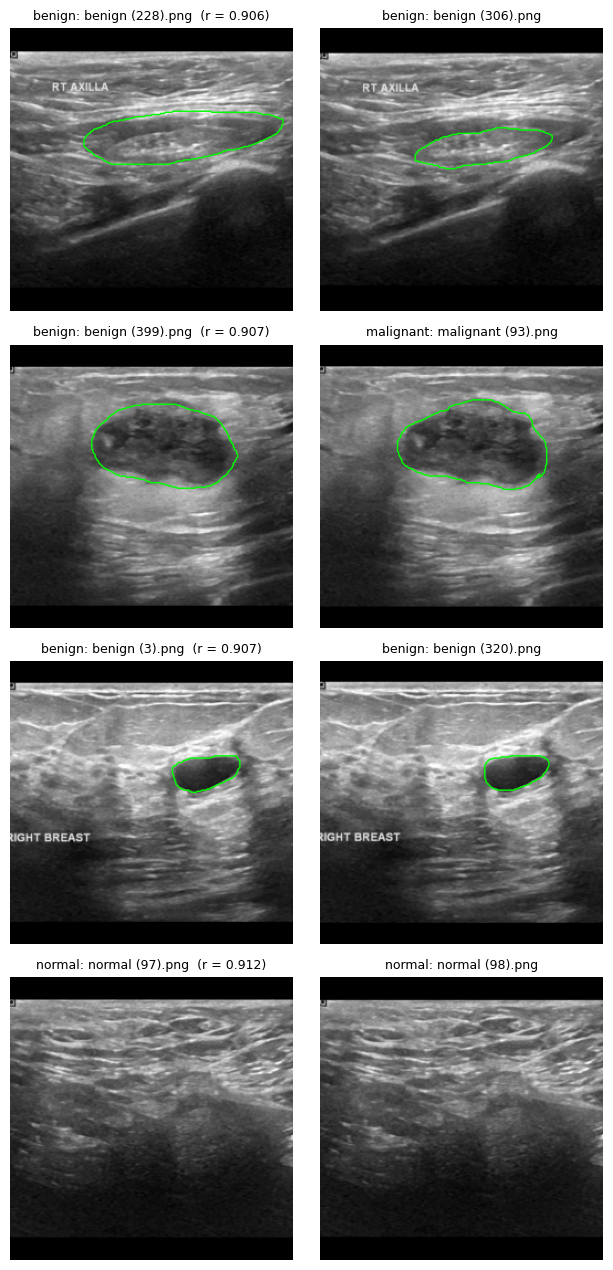

In [10]:
# least similar pairs that still pass the threshold, they should still be real copies
if len(pairs):
    lowest = pairs[np.argsort(corr[pairs[:, 0], pairs[:, 1]])[:4]]
    fig, axes = plt.subplots(len(lowest), 2, figsize=(6.5, 3.2 * len(lowest)), squeeze=False)
    for (a, b), row in zip(lowest, axes):
        show(row[0], images[a], masks[a], title=f"{df.at[a, 'label']}: {df.at[a, 'name']}  (r = {corr[a, b]:.3f})")
        show(row[1], images[b], masks[b], title=f"{df.at[b, 'label']}: {df.at[b, 'name']}")
    plt.tight_layout()
    plt.show()

Then a 70 / 15 / 15 split, stratified by class. The validation set is for choosing the best epoch, the test set is only used once at the very end.

In [11]:
clean = df[~conflict].drop_duplicates("group")   # one image per group
print("kept", len(clean), "/", len(df))

train_idx, rest = train_test_split(clean.index, test_size=0.3, stratify=clean["y"], random_state=SEED)
val_idx, test_idx = train_test_split(rest, test_size=0.5, stratify=clean.loc[rest, "y"], random_state=SEED)

df["split"] = "dropped"
df.loc[train_idx, "split"] = "train"
df.loc[val_idx, "split"] = "val"
df.loc[test_idx, "split"] = "test"
df[["name", "label", "split"]].to_csv(DATA_DIR / "busi_split.csv", index=False)
pd.crosstab(df["label"], df["split"]).reindex(index=CLASSES, columns=["train", "val", "test", "dropped"], fill_value=0)

kept 760 / 780


split,train,val,test,dropped
label,,,,
normal,90,19,19,5
benign,298,64,64,11
malignant,144,31,31,4


## 4. Dataset and augmentation

The image and its mask get the same random transform (flip, small rotation, shift, zoom) so they stay aligned. Brightness and contrast only change on the image. No vertical flip since the skin is always at the top on ultrasound. The images are grayscale, so they're copied to 3 channels for the ImageNet weights.

In [12]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)   # imagenet stats
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

augment = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.2, contrast=0.2),   # v2 leaves the Mask untouched for this one
])


def to_input(img):
    # uint8 gray image -> normalized 3 channel float tensor
    x = torch.as_tensor(img).float() / 255
    if x.ndim == 2:
        x = x[None]
    return (x.expand(3, -1, -1) - MEAN) / STD


class BreastUltrasound(Dataset):
    def __init__(self, images, masks, labels, train=False):
        self.images = images
        self.masks = masks
        self.labels = labels
        self.train = train

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = tv_tensors.Image(torch.from_numpy(self.images[i])[None])
        mask = tv_tensors.Mask(torch.from_numpy(self.masks[i])[None].to(torch.uint8))
        if self.train:
            img, mask = augment(img, mask)
        x = to_input(img.as_subclass(torch.Tensor))
        return x, mask.as_subclass(torch.Tensor).float(), int(self.labels[i])


# no worker processes: everything is already in RAM, and workers can't pickle a Dataset
# defined in a notebook on mac/windows or python >= 3.14 (spawn / forkserver)
def make_loader(split, train=False):
    idx = np.flatnonzero(df["split"] == split)
    ds = BreastUltrasound(images[idx], masks[idx], df["y"].values[idx], train)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=train, drop_last=train,
                      pin_memory=DEVICE.type == "cuda")


train_loader = make_loader("train", train=True)
val_loader = make_loader("val")
test_loader = make_loader("test")

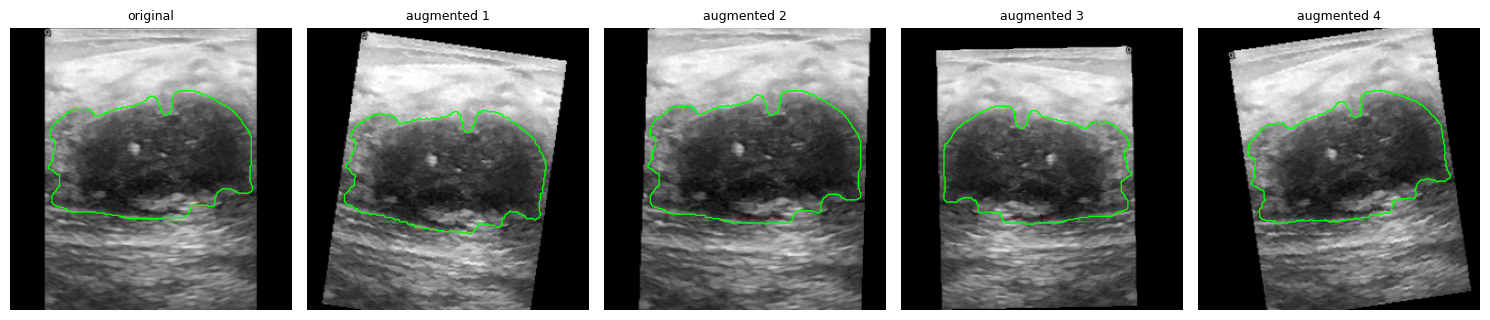

In [13]:
# what the augmentation looks like on one training image
i = np.flatnonzero((df["split"] == "train") & (df["label"] == "malignant"))[0]
one = BreastUltrasound(images[[i]], masks[[i]], [2], train=True)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
show(axes[0], images[i], masks[i], title="original")
for k in range(1, 5):
    x, m, _ = one[0]
    show(axes[k], (x * STD + MEAN)[0].clamp(0, 1), m[0], title=f"augmented {k}")
plt.tight_layout()
plt.show()

Training loop used for both models: AdamW with a cosine schedule, mixed precision on GPU, early stopping on the validation score, and at the end it reloads the weights from the best epoch.

In [14]:
def autocast():
    return torch.autocast(device_type="cuda" if USE_AMP else "cpu", enabled=USE_AMP)


def train_model(model, loss_fn, score_fn, epochs, name):
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    best_score, best_state, bad_epochs = -1, None, 0
    history = []
    t0 = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        for x, m, y in train_loader:
            x, m, y = x.to(DEVICE), m.to(DEVICE), y.to(DEVICE)
            with autocast():
                out = model(x)
            loss = loss_fn(out.float(), m, y)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            losses.append(loss.item())
        sched.step()

        score = score_fn(model, val_loader)
        history.append({"epoch": epoch, "train loss": np.mean(losses), "val score": score})
        print(f"epoch {epoch:2d}  loss {np.mean(losses):.3f}  val {score:.3f}")

        if score > best_score:
            best_score, bad_epochs = score, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs == PATIENCE:
                print("early stop")
                break

    model.load_state_dict(best_state)
    torch.save(best_state, MODEL_DIR / f"{name}.pt")
    print(f"best val {best_score:.3f} ({time.time() - t0:.0f}s), saved to {MODEL_DIR / name}.pt")
    return pd.DataFrame(history)


def plot_history(history, score_name):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
    ax1.plot(history["epoch"], history["train loss"])
    ax1.set_title("train loss")
    ax2.plot(history["epoch"], history["val score"], color="tab:orange")
    ax2.set_title("val " + score_name)
    for ax in (ax1, ax2):
        ax.set_xlabel("epoch")
    plt.tight_layout()
    plt.show()


def bootstrap_ci(metric, y, p, groups=None, n=1000):
    # 95% CI from n resamples of the test set.
    # with groups (patient ids) whole patients are resampled instead of single images
    r = np.random.default_rng(SEED)
    if groups is None:
        groups = np.arange(len(y))
    _, g = np.unique(groups, return_inverse=True)
    members = [np.flatnonzero(g == k) for k in range(g.max() + 1)]
    vals = []
    for _ in range(n):
        picked = r.integers(0, len(members), len(members))
        i = np.concatenate([members[k] for k in picked])
        if len(np.unique(y[i])) == len(np.unique(y)):   # skip resamples where a class is missing
            vals.append(metric(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])

## 5. Classifier

ResNet-34 with a new 3-class head. Benign is more than half of BUSI, so the loss uses class weights (inverse frequency), otherwise the model can mostly ignore normal and malignant. The best epoch is the one with the best macro-F1 on validation.

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 187MB/s]


epoch  1  loss 1.045  val 0.504
epoch  2  loss 0.708  val 0.670
epoch  3  loss 0.711  val 0.615
epoch  4  loss 0.542  val 0.759
epoch  5  loss 0.509  val 0.766
epoch  6  loss 0.427  val 0.845
epoch  7  loss 0.453  val 0.708
epoch  8  loss 0.494  val 0.784
epoch  9  loss 0.480  val 0.842
epoch 10  loss 0.366  val 0.831
epoch 11  loss 0.355  val 0.850
epoch 12  loss 0.374  val 0.786
epoch 13  loss 0.371  val 0.874
epoch 14  loss 0.317  val 0.726
epoch 15  loss 0.325  val 0.864
epoch 16  loss 0.294  val 0.889
epoch 17  loss 0.280  val 0.852
epoch 18  loss 0.283  val 0.876
epoch 19  loss 0.258  val 0.869
epoch 20  loss 0.262  val 0.895
epoch 21  loss 0.247  val 0.911
epoch 22  loss 0.262  val 0.898
epoch 23  loss 0.261  val 0.908
epoch 24  loss 0.242  val 0.918
epoch 25  loss 0.245  val 0.911
epoch 26  loss 0.248  val 0.898
epoch 27  loss 0.244  val 0.911
epoch 28  loss 0.245  val 0.911
epoch 29  loss 0.239  val 0.903
epoch 30  loss 0.240  val 0.911
best val 0.918 (150s), saved to models/c

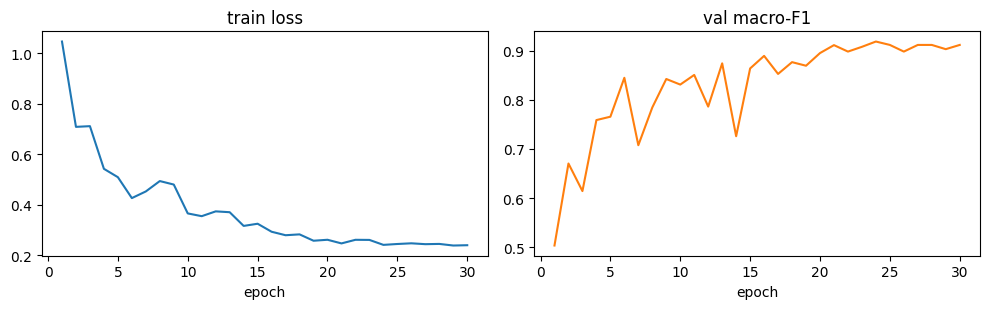

In [15]:
def resnet34_backbone():
    weights = ResNet34_Weights.IMAGENET1K_V1 if PRETRAINED else None
    return resnet34(weights=weights)


classifier = resnet34_backbone()
classifier.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, len(CLASSES)))
classifier = classifier.to(DEVICE)

train_y = df.loc[df["split"] == "train", "y"].values
counts = np.bincount(train_y, minlength=len(CLASSES))
class_w = torch.tensor(len(train_y) / (len(CLASSES) * counts), dtype=torch.float32)
criterion = nn.CrossEntropyLoss(weight=class_w.to(DEVICE), label_smoothing=0.05)


@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    probs, ys = [], []
    for x, _, y in loader:
        with autocast():
            logits = model(x.to(DEVICE))
        probs.append(logits.float().softmax(1).cpu())
        ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


def val_f1(model, loader):
    p, y = predict_probs(model, loader)
    return f1_score(y, p.argmax(1), average="macro")


cls_history = train_model(classifier, lambda out, m, y: criterion(out, y), val_f1, EPOCHS_CLS, "classifier_resnet34")
plot_history(cls_history, "macro-F1")

### Results on the test set

Malignant sensitivity = share of malignant images predicted malignant, malignant specificity = share of the other images not predicted malignant. The 95% CIs come from 1000 bootstrap resamples of the test set.

In [16]:
p_test, y_test = predict_probs(classifier, test_loader)
pred_test = p_test.argmax(1)
print(len(y_test), "test images")

metrics = {
    "accuracy": lambda y, p: accuracy_score(y, p.argmax(1)),
    "balanced accuracy": lambda y, p: balanced_accuracy_score(y, p.argmax(1)),
    "macro-F1": lambda y, p: f1_score(y, p.argmax(1), average="macro"),
    "ROC-AUC (one vs rest)": lambda y, p: roc_auc_score(y, p, multi_class="ovr"),
    "malignant sensitivity": lambda y, p: np.mean(p[y == 2].argmax(1) == 2),
    "malignant specificity": lambda y, p: np.mean(p[y != 2].argmax(1) != 2),
}
rows = []
for name, f in metrics.items():
    lo, hi = bootstrap_ci(f, y_test, p_test)
    rows.append({"metric": name, "value": round(f(y_test, p_test), 3), "95% CI": f"[{lo:.3f}, {hi:.3f}]"})
cls_results = pd.DataFrame(rows).set_index("metric")
cls_results

114 test images


,value,95% CI
metric,,
accuracy,0.886,"[0.833, 0.947]"
balanced accuracy,0.887,"[0.824, 0.944]"
macro-F1,0.864,"[0.795, 0.932]"
ROC-AUC (one vs rest),0.980,"[0.960, 0.995]"
malignant sensitivity,0.806,"[0.667, 0.938]"
malignant specificity,0.940,"[0.885, 0.988]"


              precision    recall  f1-score   support

      normal      0.750     0.947     0.837        19
      benign      0.967     0.906     0.935        64
   malignant      0.833     0.806     0.820        31

    accuracy                          0.886       114
   macro avg      0.850     0.887     0.864       114
weighted avg      0.894     0.886     0.888       114



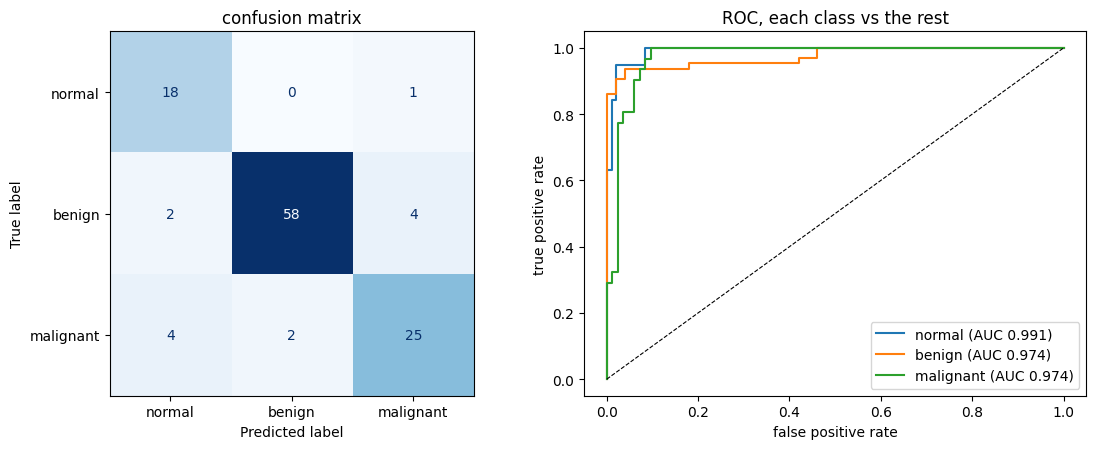

In [17]:
print(classification_report(y_test, pred_test, target_names=CLASSES, digits=3, zero_division=0))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.6))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=CLASSES, cmap="Blues",
                                        colorbar=False, ax=ax1)
ax1.set_title("confusion matrix")
for k, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_test == k, p_test[:, k])
    auc = roc_auc_score(y_test == k, p_test[:, k])
    ax2.plot(fpr, tpr, label=f"{c} (AUC {auc:.3f})")
ax2.plot([0, 1], [0, 1], "k--", lw=0.8)
ax2.set_xlabel("false positive rate")
ax2.set_ylabel("true positive rate")
ax2.set_title("ROC, each class vs the rest")
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Grad-CAM

Grad-CAM ([Selvaraju et al., 2017](https://arxiv.org/abs/1610.02391)) shows which regions the prediction relies on. I use it as a sanity check: the heatmap should be on the lesion (green), not on the text and caliper marks you can see on a lot of BUSI images.

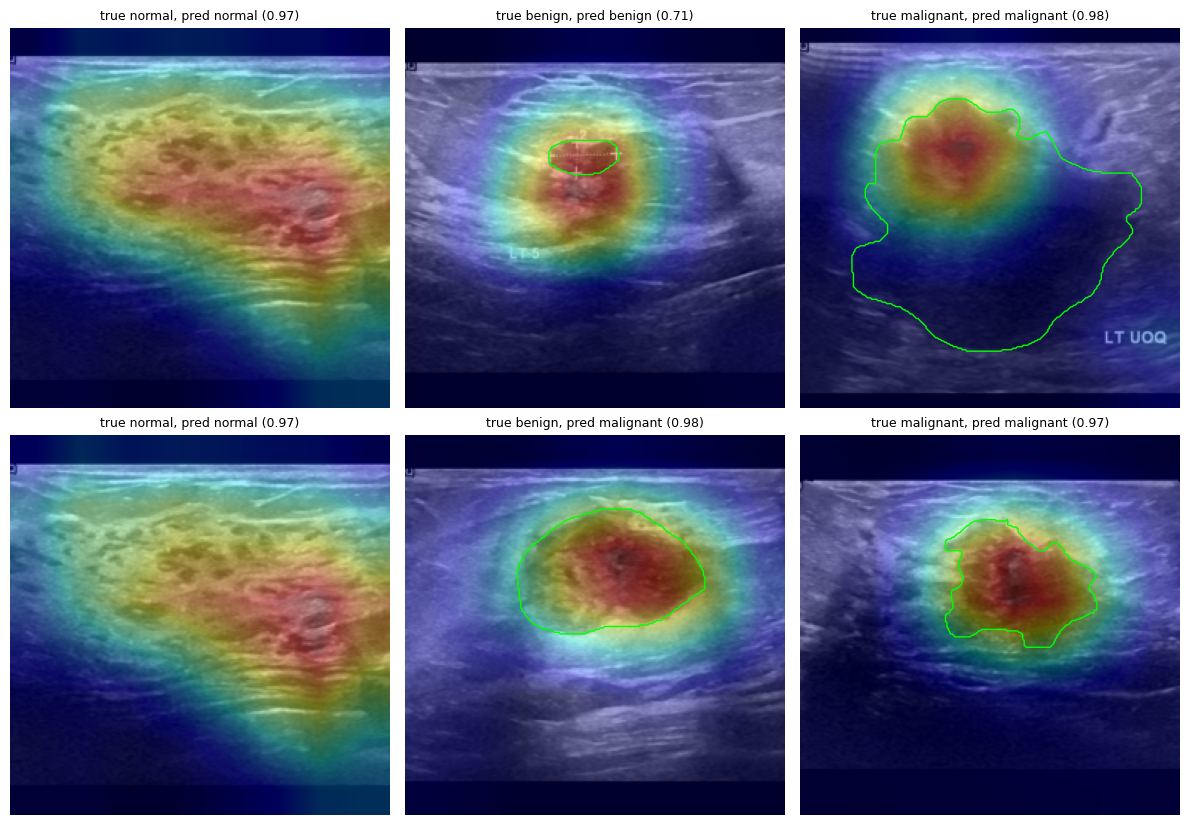

In [18]:
def grad_cam(model, x, layer):
    saved = {}

    def hook(module, inp, out):
        saved["act"] = out
        out.register_hook(lambda g: saved.update(grad=g))

    h = layer.register_forward_hook(hook)
    model.eval()
    try:
        logits = model(x[None].to(DEVICE))
    finally:
        h.remove()
    probs = logits.softmax(1)[0].detach().cpu().numpy()
    cls = int(probs.argmax())
    model.zero_grad()
    logits[0, cls].backward()

    w = saved["grad"].mean(dim=(2, 3), keepdim=True)   # one weight per channel
    cam = F.relu((w * saved["act"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = cam / (cam.max() + 1e-8)
    return cam.detach().cpu().numpy(), cls, probs


test_ids = np.flatnonzero(df["split"] == "test")
y_all = df["y"].values

fig, axes = plt.subplots(2, 3, figsize=(12, 8.4))
for k in range(len(CLASSES)):
    ids = test_ids[y_all[test_ids] == k]
    for row, i in enumerate(rng.choice(ids, min(2, len(ids)), replace=False)):
        cam, cls, probs = grad_cam(classifier, to_input(images[i]), classifier.layer4)
        ax = axes[row, k]
        ax.imshow(images[i], cmap="gray")
        ax.imshow(cam, cmap="jet", alpha=0.35)
        if masks[i].any():
            ax.contour(masks[i], levels=[0.5], colors="lime", linewidths=1)
        ax.set_title(f"true {CLASSES[k]}, pred {CLASSES[cls]} ({probs[cls]:.2f})", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. U-Net

U-Net ([Ronneberger et al., 2015](https://arxiv.org/abs/1505.04597)) where the encoder is the same pretrained ResNet-34. I train it on every image, normal ones included. Their mask is empty, so the model also learns to predict nothing when there's no lesion.

The loss is BCE + Dice. On validation I use the mean Dice over all images (an empty prediction on a normal image counts as 1). Blobs smaller than `MIN_LESION_PX` pixels are removed from the predictions.

epoch  1  loss 1.383  val 0.313
epoch  2  loss 1.278  val 0.583
epoch  3  loss 1.242  val 0.680
epoch  4  loss 1.199  val 0.651
epoch  5  loss 1.168  val 0.639
epoch  6  loss 1.142  val 0.694
epoch  7  loss 1.114  val 0.618
epoch  8  loss 1.086  val 0.680
epoch  9  loss 1.064  val 0.590
epoch 10  loss 1.033  val 0.666
epoch 11  loss 1.013  val 0.650
epoch 12  loss 0.985  val 0.693
epoch 13  loss 0.957  val 0.731
epoch 14  loss 0.934  val 0.757
epoch 15  loss 0.906  val 0.721
epoch 16  loss 0.894  val 0.755
epoch 17  loss 0.870  val 0.767
epoch 18  loss 0.857  val 0.745
epoch 19  loss 0.839  val 0.749
epoch 20  loss 0.820  val 0.763
epoch 21  loss 0.807  val 0.781
epoch 22  loss 0.793  val 0.797
epoch 23  loss 0.781  val 0.798
epoch 24  loss 0.771  val 0.781
epoch 25  loss 0.755  val 0.798
epoch 26  loss 0.748  val 0.772
epoch 27  loss 0.740  val 0.767
epoch 28  loss 0.728  val 0.772
epoch 29  loss 0.723  val 0.776
epoch 30  loss 0.715  val 0.788
epoch 31  loss 0.712  val 0.791
epoch 32

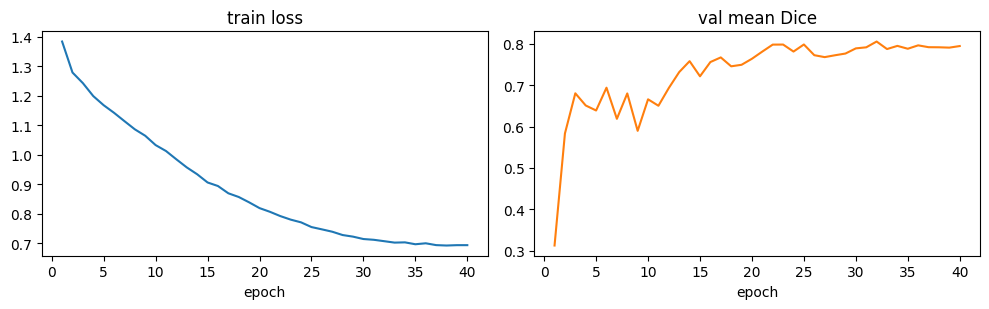

In [19]:
class Up(nn.Module):
    # upsample x2, concat the skip connection, then 2x conv-bn-relu
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch + skip_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        r = resnet34_backbone()
        # encoder = resnet34 without the avgpool and fc
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu)   # 1/2
        self.pool = r.maxpool
        self.enc1 = r.layer1   # 1/4, 64 ch
        self.enc2 = r.layer2   # 1/8, 128 ch
        self.enc3 = r.layer3   # 1/16, 256 ch
        self.enc4 = r.layer4   # 1/32, 512 ch
        self.up4 = Up(512, 256, 256)
        self.up3 = Up(256, 128, 128)
        self.up2 = Up(128, 64, 64)
        self.up1 = Up(64, 64, 32)
        self.up0 = Up(32, 0, 16)   # back to full size, no skip at this level
        self.head = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        s = self.stem(x)
        e1 = self.enc1(self.pool(s))
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        d = self.up4(e4, e3)
        d = self.up3(d, e2)
        d = self.up2(d, e1)
        d = self.up1(d, s)
        d = self.up0(d)
        return self.head(d)


def seg_loss(logits, target):
    # bce + soft dice, dice is computed per image then averaged
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum((1, 2, 3))
    dice = (2 * inter + 1) / (prob.sum((1, 2, 3)) + target.sum((1, 2, 3)) + 1)
    return F.binary_cross_entropy_with_logits(logits, target) + (1 - dice).mean()


def clean_mask(mask):
    # remove small isolated blobs
    labels, n = ndimage.label(mask)
    if n == 0:
        return mask
    sizes = ndimage.sum(mask, labels, range(1, n + 1))
    keep = np.flatnonzero(sizes >= MIN_LESION_PX) + 1
    return np.isin(labels, keep)


@torch.no_grad()
def predict_masks(model, loader):
    model.eval()
    preds = []
    for x, _, _ in loader:
        with autocast():
            logits = model(x.to(DEVICE))
        prob = torch.sigmoid(logits.float())[:, 0].cpu().numpy()
        preds += [clean_mask(p > 0.5) for p in prob]
    return np.stack(preds)


def dice_iou(pred, gt):
    inter = (pred & gt).sum()
    total = pred.sum() + gt.sum()
    if total == 0:   # normal image and nothing predicted
        return 1.0, 1.0
    return 2 * inter / total, inter / (total - inter)


def val_dice(model, loader):
    preds = predict_masks(model, loader)
    return np.mean([dice_iou(p, g)[0] for p, g in zip(preds, loader.dataset.masks)])


unet = UNet().to(DEVICE)
seg_history = train_model(unet, lambda out, m, y: seg_loss(out, m), val_dice, EPOCHS_SEG, "unet_resnet34")
plot_history(seg_history, "mean Dice")

### Results on the test set

Dice and IoU are only computed on the images that have a lesion (1 = perfect overlap, 0 = none). For the normal images I just count how often the U-Net predicts a lesion that isn't there.

In [20]:
pred_masks = predict_masks(unet, test_loader)
test_df = df[df["split"] == "test"].copy()
scores = [dice_iou(p, g) for p, g in zip(pred_masks, masks[test_df.index])]
test_df["dice"] = [s[0] for s in scores]
test_df["iou"] = [s[1] for s in scores]
test_df["pred_px"] = pred_masks.sum((1, 2))
lesion = (test_df["label"] != "normal").values

rows = []
for name, sel in [("benign", test_df["label"] == "benign"),
                  ("malignant", test_df["label"] == "malignant"),
                  ("all lesions", lesion)]:
    d = test_df.loc[sel, "dice"].values
    lo, hi = bootstrap_ci(lambda y, p: p.mean(), test_df.loc[sel, "y"].values, d)
    rows.append({"lesions": name, "n": len(d), "mean Dice": round(d.mean(), 3),
                 "95% CI": f"[{lo:.3f}, {hi:.3f}]", "mean IoU": round(test_df.loc[sel, "iou"].mean(), 3)})
seg_results = pd.DataFrame(rows).set_index("lesions")

false_alarms = (test_df.loc[~lesion, "pred_px"] > 0).sum()
print(f"normal test images where the unet still predicts a lesion: {false_alarms}/{(~lesion).sum()}")
seg_results

normal test images where the unet still predicts a lesion: 4/19


,n,mean Dice,95% CI,mean IoU
lesions,,,,
benign,64,0.851,"[0.798, 0.892]",0.774
malignant,31,0.715,"[0.607, 0.810]",0.621
all lesions,95,0.806,"[0.757, 0.850]",0.724


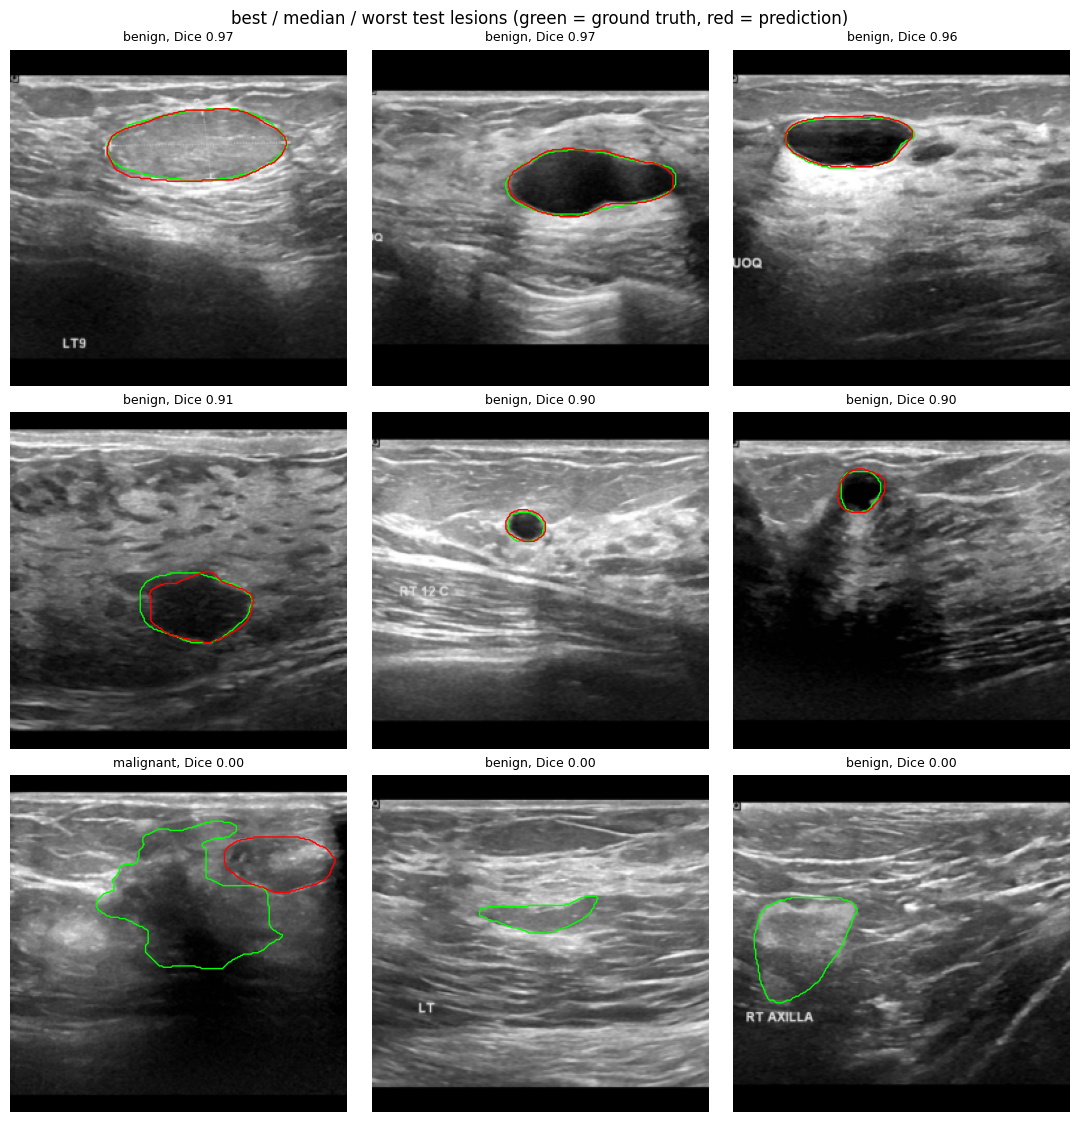

In [21]:
ranked = test_df[lesion].sort_values("dice", ascending=False)
mid = len(ranked) // 2
shown = pd.concat([ranked.head(3), ranked.iloc[max(mid - 1, 0):mid + 2], ranked.tail(3)])
shown = shown[~shown.index.duplicated()]   # can overlap if the test set is small

fig, axes = plt.subplots(3, 3, figsize=(11, 11.4))
for ax in axes.flat:
    ax.axis("off")
for ax, (i, r) in zip(axes.flat, shown.iterrows()):
    k = test_df.index.get_loc(i)
    show(ax, images[i], masks[i], pred_masks[k], title=f"{r['label']}, Dice {r['dice']:.2f}")
plt.suptitle("best / median / worst test lesions (green = ground truth, red = prediction)")
plt.tight_layout()
plt.show()

## 7. Both models on one image

`analyze` returns the class probabilities, the Grad-CAM map and the predicted mask for one preprocessed image. To try it on another scan: `analyze(pad_resize(load_gray("scan.png"), IMG_SIZE))`.

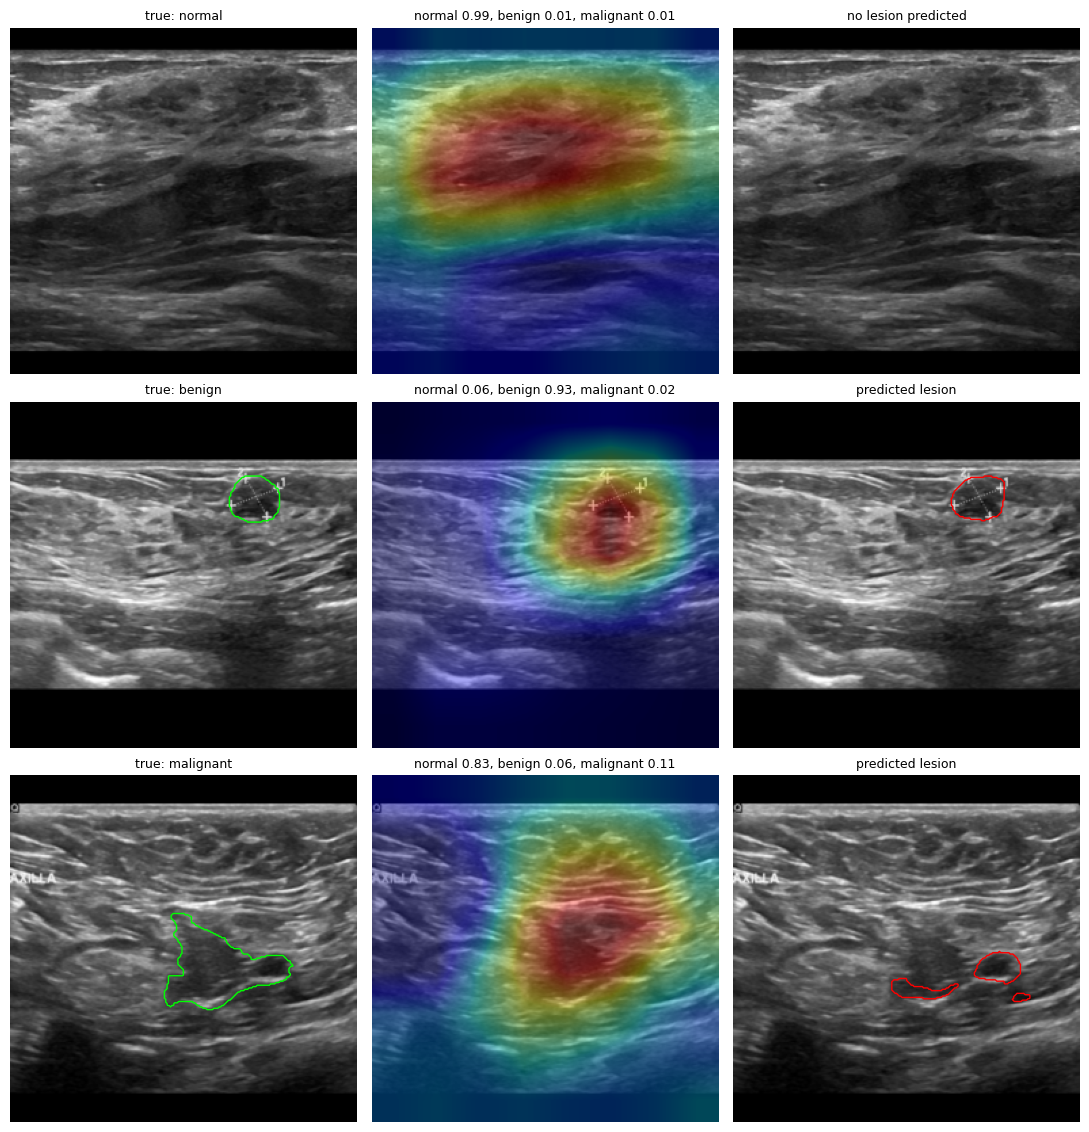

In [22]:
def analyze(img):
    # img = uint8 image already padded and resized to IMG_SIZE
    x = to_input(img)
    cam, cls, probs = grad_cam(classifier, x, classifier.layer4)
    unet.eval()
    with torch.no_grad():
        prob = torch.sigmoid(unet(x[None].to(DEVICE)))[0, 0].cpu().numpy()
    return probs, cam, clean_mask(prob > 0.5)


fig, axes = plt.subplots(3, 3, figsize=(11, 11.4))
for k, row in enumerate(axes):
    i = rng.choice(test_ids[y_all[test_ids] == k])
    probs, cam, pred = analyze(images[i])
    show(row[0], images[i], masks[i], title=f"true: {CLASSES[k]}")
    row[1].imshow(images[i], cmap="gray")
    row[1].imshow(cam, cmap="jet", alpha=0.35)
    row[1].set_title(", ".join(f"{c} {p:.2f}" for c, p in zip(CLASSES, probs)), fontsize=9)
    row[1].axis("off")
    show(row[2], images[i], pred=pred, title="predicted lesion" if pred.any() else "no lesion predicted")
plt.tight_layout()
plt.show()

## 8. External test (BUS-BRA)

BUS-BRA is a different hospital, with different machines and patients. It has no normal images, so I only look at benign vs malignant, using the predicted probability of malignant. The scores will probably be lower than on BUSI, and how much lower tells how much the models depend on where the training data came from.

Some patients have several images, so for the confidence interval I resample patients instead of images.

Downloaded from [Zenodo](https://doi.org/10.5281/zenodo.8231412) (134 MB, CC BY 4.0).

In [23]:
BUSBRA_URL = "https://zenodo.org/records/8231412/files/BUSBRA.zip?download=1"
BUSBRA_MD5 = "1f8b2be6476d58fc97bfb5e5a1ea9bab"


def get_busbra():
    if BUSBRA_DIR is not None:
        return next(Path(BUSBRA_DIR).rglob("bus_data.csv")).parent
    root = DATA_DIR / "BUSBRA"
    if not (root / "bus_data.csv").exists():
        zip_path = DATA_DIR / "BUSBRA.zip"
        if not zip_path.exists():
            print("downloading BUS-BRA (134 MB)...")
            urllib.request.urlretrieve(BUSBRA_URL, zip_path)
        md5 = hashlib.md5(zip_path.read_bytes()).hexdigest()
        if md5 != BUSBRA_MD5:
            raise ValueError(f"wrong checksum for {zip_path} ({md5}), delete it and run again")
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(DATA_DIR)   # the zip contains a BUSBRA/ folder
    return root


busbra_root = None
if RUN_EXTERNAL_TEST:
    try:
        busbra_root = get_busbra()
        print(busbra_root)
    except Exception as e:   # no internet, zenodo down, ...
        print("skipping the external test:", e)

downloading BUS-BRA (134 MB)...
data/BUSBRA


In [24]:
def lesion_metrics(y, p, scores):
    malignant = y == 2
    pred = p.argmax(1)
    return {
        "ROC-AUC malignant vs benign": roc_auc_score(malignant, p[:, 2]),
        "malignant sensitivity": np.mean(pred[malignant] == 2),
        "benign specificity": np.mean(pred[~malignant] != 2),
        "lesions predicted normal": np.mean(pred == 0),
        "mean Dice": scores[:, 0].mean(),
        "mean IoU": scores[:, 1].mean(),
    }


if busbra_root is not None:
    bb = pd.read_csv(busbra_root / "bus_data.csv")
    bb["y"] = np.where(bb["Pathology"] == "malignant", 2, 1)
    print(len(bb), "images,", bb["Case"].nunique(), "patients")
    print(bb["Pathology"].value_counts().to_string())

    bb_images, bb_masks = [], []
    for id_ in bb["ID"]:
        # bus_0001-l.png -> mask_0001-l.png
        mask_path = busbra_root / "Masks" / (id_.replace("bus", "mask", 1) + ".png")
        img, mask = load_case(busbra_root / "Images" / f"{id_}.png", [mask_path])
        bb_images.append(img)
        bb_masks.append(mask)
    bb_images, bb_masks = np.stack(bb_images), np.stack(bb_masks)
    bb_loader = DataLoader(BreastUltrasound(bb_images, bb_masks, bb["y"].values), batch_size=BATCH_SIZE)

    p_bb, y_bb = predict_probs(classifier, bb_loader)
    bb_pred = predict_masks(unet, bb_loader)
    bb_scores = np.array([dice_iou(p, g) for p, g in zip(bb_pred, bb_masks)])

    busi_scores = test_df.loc[lesion, ["dice", "iou"]].values
    external = pd.DataFrame({
        f"BUSI test ({lesion.sum()} lesions)": lesion_metrics(y_test[lesion], p_test[lesion], busi_scores),
        f"BUS-BRA ({len(bb)} lesions)": lesion_metrics(y_bb, p_bb, bb_scores),
    }).round(3)

    lo, hi = bootstrap_ci(lambda y, p: roc_auc_score(y == 2, p[:, 2]), y_bb, p_bb, groups=bb["Case"].values)
    print(f"BUS-BRA ROC-AUC 95% CI (resampling patients): [{lo:.3f}, {hi:.3f}]")
    display(external)

1875 images, 1064 patients
Pathology
benign       1268
malignant     607
BUS-BRA ROC-AUC 95% CI (resampling patients): [0.674, 0.735]


,BUSI test (95 lesions),BUS-BRA (1875 lesions)
ROC-AUC malignant vs benign,0.970,0.706
malignant sensitivity,0.806,0.473
benign specificity,0.938,0.811
lesions predicted normal,0.063,0.175
mean Dice,0.806,0.699
mean IoU,0.724,0.594


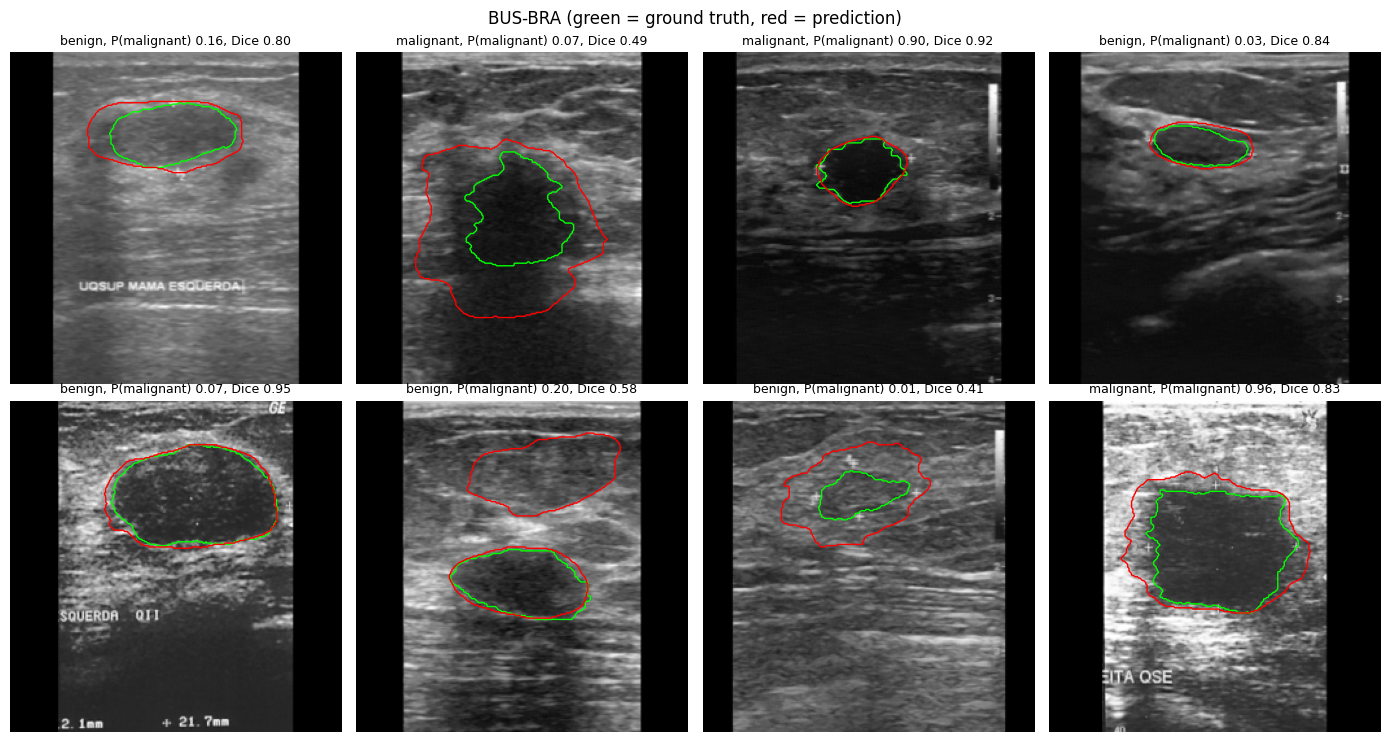

In [25]:
if busbra_root is not None:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.6))
    for ax, i in zip(axes.flat, rng.choice(len(bb), 8, replace=False)):
        title = f"{bb.at[i, 'Pathology']}, P(malignant) {p_bb[i, 2]:.2f}, Dice {bb_scores[i, 0]:.2f}"
        show(ax, bb_images[i], bb_masks[i], bb_pred[i], title=title)
    plt.suptitle("BUS-BRA (green = ground truth, red = prediction)")
    plt.tight_layout()
    plt.show()

## 9. Summary

In [26]:
print("Classification, BUSI test set")
display(cls_results)
print("Segmentation, BUSI test set")
display(seg_results)
print(f"normal test images with a predicted lesion: {false_alarms}/{(~lesion).sum()}")
if busbra_root is not None:
    print("Lesions only, BUSI test vs BUS-BRA")
    display(external)

Classification, BUSI test set


,value,95% CI
metric,,
accuracy,0.886,"[0.833, 0.947]"
balanced accuracy,0.887,"[0.824, 0.944]"
macro-F1,0.864,"[0.795, 0.932]"
ROC-AUC (one vs rest),0.980,"[0.960, 0.995]"
malignant sensitivity,0.806,"[0.667, 0.938]"
malignant specificity,0.940,"[0.885, 0.988]"


Segmentation, BUSI test set


,n,mean Dice,95% CI,mean IoU
lesions,,,,
benign,64,0.851,"[0.798, 0.892]",0.774
malignant,31,0.715,"[0.607, 0.810]",0.621
all lesions,95,0.806,"[0.757, 0.850]",0.724


normal test images with a predicted lesion: 4/19
Lesions only, BUSI test vs BUS-BRA


,BUSI test (95 lesions),BUS-BRA (1875 lesions)
ROC-AUC malignant vs benign,0.970,0.706
malignant sensitivity,0.806,0.473
benign specificity,0.938,0.811
lesions predicted normal,0.063,0.175
mean Dice,0.806,0.699
mean IoU,0.724,0.594


### Limits

- The test set is small (15% of the cleaned BUSI) so the confidence intervals are wide. Cross-validation would give more reliable numbers.
- BUSI doesn't give patient IDs, so two images of the same woman can end up one in train and one in test.
- All the training data comes from a single hospital (section 8 shows what happens elsewhere).
- Besides the duplicates, the [2023 letter](https://doi.org/10.1016/j.dib.2023.109247) found at least 19 doubtful labels, 70 images of the armpit instead of the breast, and lots of images with text, measurements or calipers drawn on them. The CNN could learn those marks instead of the lesion, which is why I look at Grad-CAM. There's a [curated BUSI](https://doi.org/10.5281/zenodo.19047974) (Aumente-Maestro et al.) with these images removed.
- Not validated for any clinical use.

### References

- W. Al-Dhabyani, M. Gomaa, H. Khaled, A. Fahmy. *Dataset of breast ultrasound images.* Data in Brief 28, 104863 (2020).
- A. Pawłowska, A. Karwat, N. Żołek. *Letter to the Editor. Re: "Dataset of breast ultrasound images".* Data in Brief 48, 109247 (2023).
- W. Gómez-Flores, M. J. Gregorio-Calas, W. C. de Albuquerque Pereira. *BUS-BRA: A breast ultrasound dataset for assessing computer-aided diagnosis systems.* Medical Physics 51(4), 3110-3123 (2024).
- K. He, X. Zhang, S. Ren, J. Sun. *Deep residual learning for image recognition.* CVPR (2016).
- O. Ronneberger, P. Fischer, T. Brox. *U-Net: Convolutional networks for biomedical image segmentation.* MICCAI (2015).
- R. R. Selvaraju et al. *Grad-CAM: Visual explanations from deep networks via gradient-based localization.* ICCV (2017).